# Cookie Cats: did moving the first gate hurt player retention?

**Cookie Cats** is a mobile puzzle game. As players progress, they hit gates where they must wait (or pay) before they can keep playing. The first gate was at level 30. The developers ran an A/B test: new players were randomly split into two groups.

- `gate_30`: the first gate stays at level 30 (the control group)
- `gate_40`: the first gate is moved to level 40 (the test group)

**The question:** does moving the "pay-gate" to level 40 change how many players come back after 1 day and after 7 days?

**Data:** I used a public dataset of 90,189 players (originally from a DataCamp project). Each row is one player.

| Column | Meaning |
|---|---|
| `userid` | player id |
| `version` | which group the player was in |
| `sum_gamerounds` | rounds played in the first 14 days |
| `retention_1` | did the player come back 1 day after installing? |
| `retention_7` | did the player come back 7 days after installing? |

In [ ]:
%pip install duckdb scipy
import pandas as pd
import matplotlib.pyplot as plt
import duckdb
from scipy.stats import chi2_contingency

plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False})

df = pd.read_csv("data/cookie_cats.csv")
df.head()

ModuleNotFoundError: No module named 'duckdb'

## 1. Check the data

In [ ]:
print("Rows:", len(df))
print("Unique players:", df["userid"].nunique())
print("Missing values:", df.isna().sum().sum())
df["version"].value_counts()

Rows: 90189
Unique players: 90189
Missing values: 0


version
gate_40    45489
gate_30    44700
Name: count, dtype: int64

Every player appears once, nothing is missing, and the two groups are just about the same size (44,700 vs 45,489). This is ideal in a random split: the groups should be comparable, so any difference in retention comes from the gate and not from who ended up in which group.

In [ ]:
df["sum_gamerounds"].describe()

count    90189.000000
mean        51.872457
std        195.050858
min          0.000000
25%          5.000000
50%         16.000000
75%         51.000000
max      49854.000000
Name: sum_gamerounds, dtype: float64

The number of rounds played is very uneven:
- Half of all players played 16 rounds or fewer.
- Some players played 0 rounds: they installed the game but never really started. This is typical for mobile games.
- One player played 49,854 rounds in 14 days, which is likely a bot or a tracking error. Points to non-human behavior.

That one extreme value doesn't affect retention (it's just one player out of 90,000), so I opted to keep everyone in the retention analysis. I cut the chart at 100 rounds so it's easier to read.

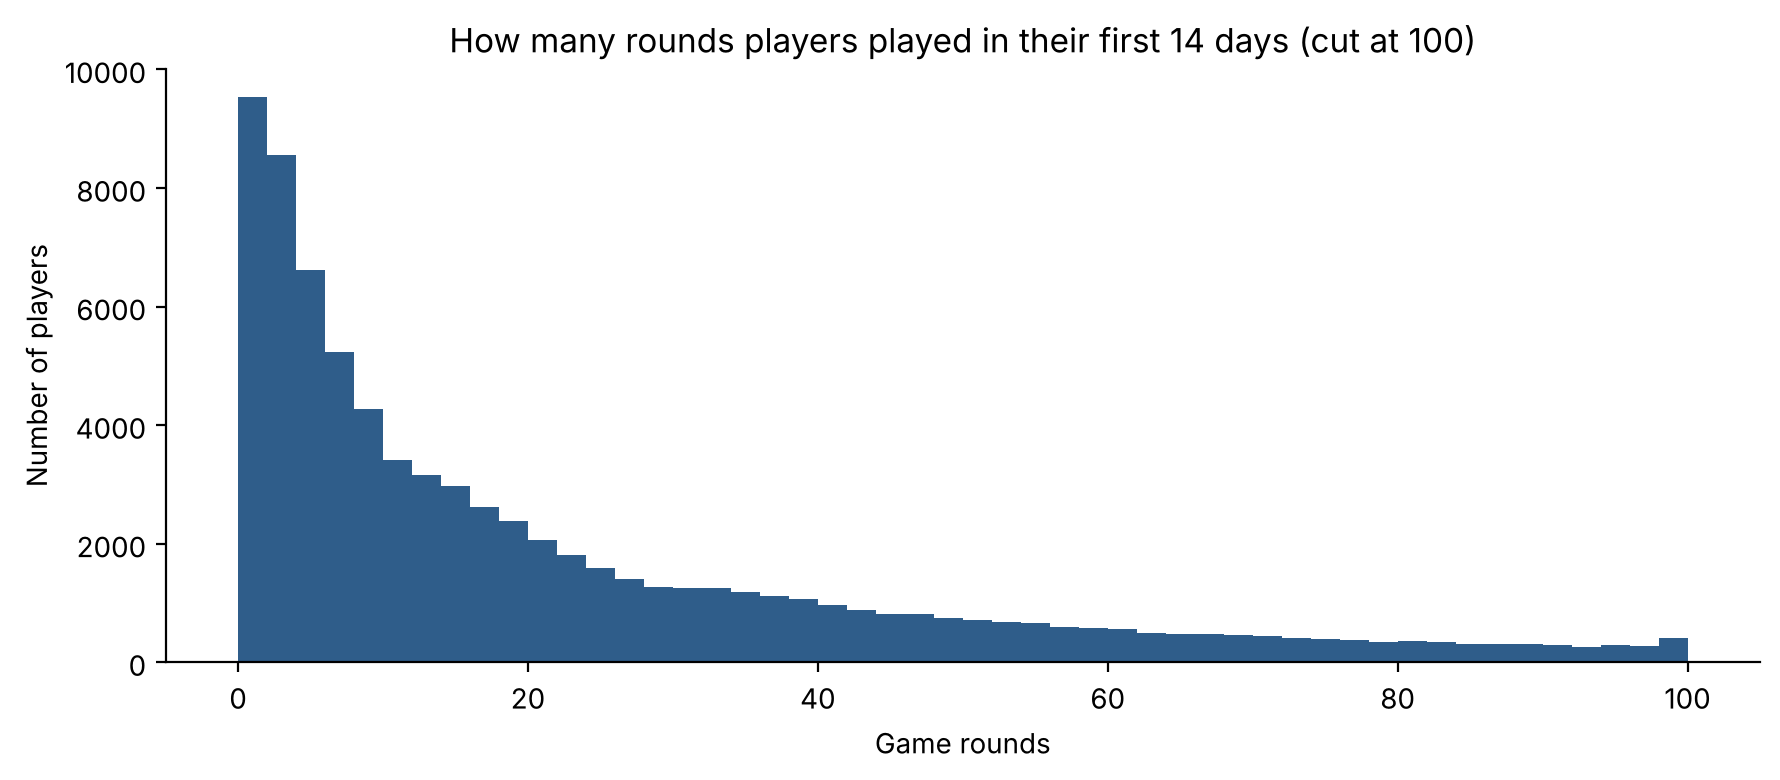

In [ ]:
fig, ax = plt.subplots(figsize=(9, 4))
df[df["sum_gamerounds"] <= 100]["sum_gamerounds"].hist(bins=50, ax=ax, color="#2f5d8a", grid=False)
ax.set_title("How many rounds players played in their first 14 days (cut at 100)")
ax.set_xlabel("Game rounds")
ax.set_ylabel("Number of players")
plt.tight_layout()
plt.savefig("figures/game_rounds.png", dpi=150)
plt.show()

Most players drop off early, and a large share play only a handful of rounds. This is typical for mobile games, and it's why early retention matters so much.

## 2. Retention per group

First with SQL. I used DuckDB to query a pandas DataFrame directly, as if it were a database table. `True` counts as 1 and `False` as 0, so the average of a True/False column is the share of players who came back.

In [ ]:
retention = duckdb.sql("""
    select
        version,
        count(*)                                   as players,
        round(avg(retention_1::int) * 100, 2)      as day1_retention_pct,
        round(avg(retention_7::int) * 100, 2)      as day7_retention_pct
    from df
    group by version
    order by version
""").df()
retention

,version,players,day1_retention_pct,day7_retention_pct
0,gate_30,44700,44.82,19.02
1,gate_40,45489,44.23,18.20


The same calculation in pandas, to check that they match: 

In [ ]:
(df.groupby("version")[["retention_1", "retention_7"]].mean() * 100).round(2)

,retention_1,retention_7
version,,
gate_30,44.82,19.02
gate_40,44.23,18.20


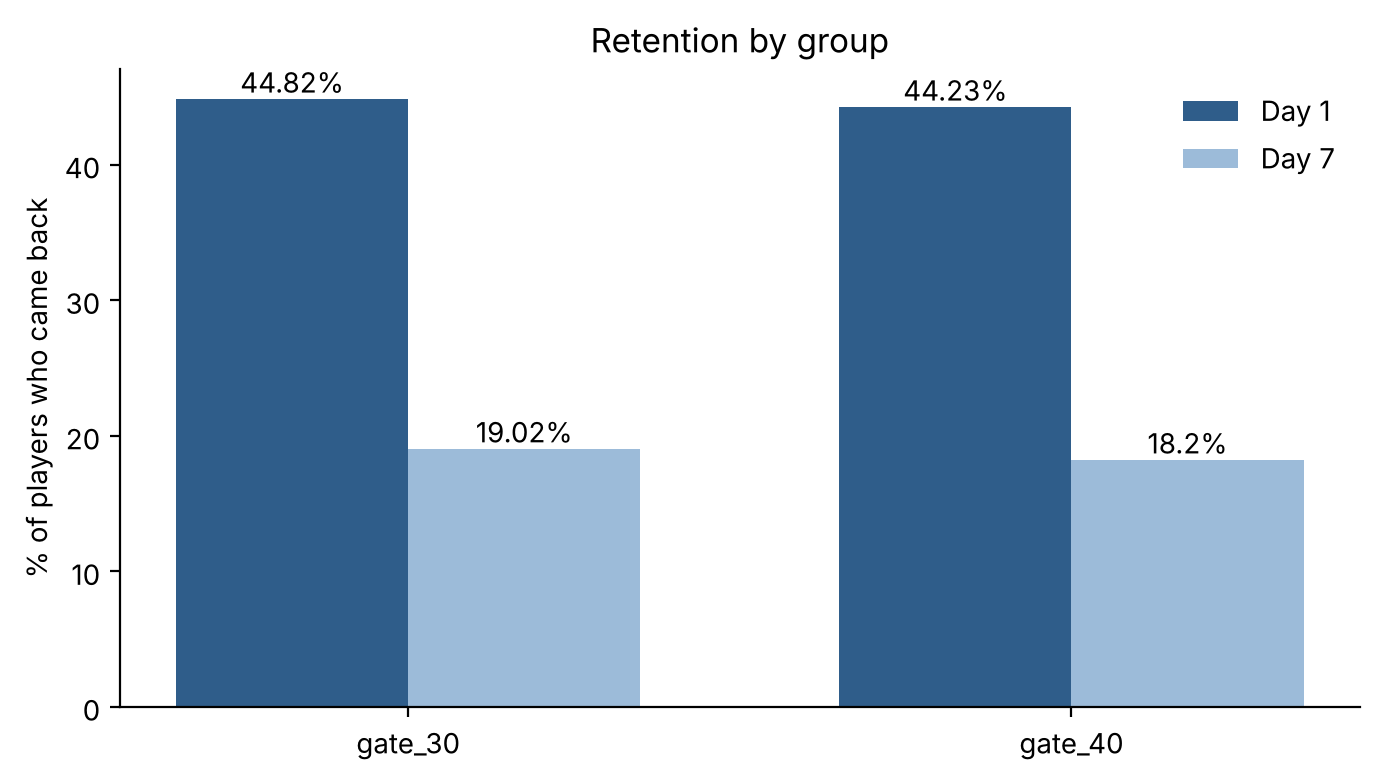

In [ ]:
fig, ax = plt.subplots(figsize=(7, 4))
x = range(2)
w = 0.35
ax.bar([i - w/2 for i in x], retention["day1_retention_pct"], w, label="Day 1", color="#2f5d8a")
ax.bar([i + w/2 for i in x], retention["day7_retention_pct"], w, label="Day 7", color="#9cbbd9")
ax.set_xticks(list(x))
ax.set_xticklabels(retention["version"])
ax.set_ylabel("% of players who came back")
ax.set_title("Retention by group")
ax.legend(frameon=False)
for i, row in retention.iterrows():
    ax.text(i - w/2, row["day1_retention_pct"] + 0.5, f'{row["day1_retention_pct"]}%', ha="center")
    ax.text(i + w/2, row["day7_retention_pct"] + 0.5, f'{row["day7_retention_pct"]}%', ha="center")
plt.tight_layout()
plt.savefig("figures/retention_by_group.png", dpi=150)
plt.show()

With the gate at level 40, retention is slightly lower on both days:
- Day 1: 44.8% -> 44.2% (−0.6 percentage points)
- Day 7: 19.0% -> 18.2% (−0.8 percentage points)

The differences are small. The question is whether they are real, or just random noise from which players happened to end up in which group.

## 3. Is the difference real?

To check this, I used a chi-square test. It asks: "If the gate made no difference at all, how likely is it that we'd see a gap this big just by chance?" That probability is the p-value which is the result of the test. A common rule is that if p is below 0.05 (5%), we treat the difference as real (statistically significant).

In [ ]:
for column in ["retention_1", "retention_7"]:
    table = pd.crosstab(df["version"], df[column])   # counts: came back / didn't, per group
    p_value = chi2_contingency(table)[1]
    verdict = "significant" if p_value < 0.05 else "not significant"
    print(f"{column}: p = {p_value:.4f} -> {verdict}")

NameError: name 'df' is not defined

- Day 1: p ≈ 0.08, which is **not significant**. The small drop could here could be chance. 
- Day 7: p ≈ 0.002, which is **significant**. A drop this big would happen by chance only about 2 times in 1,000 if the gate had no effect

## 4. Conclusion

| | gate_30 | gate_40 | Real difference? |
|---|---|---|---|
| Day 1 retention | 44.8% | 44.2% | No (p ≈ 0.08) |
| Day 7 retention | 19.0% | 18.2% | Yes (p ≈ 0.002) |

Recommendation: for this situation, keep the gate at level 30. Moving it to level 40 did not change whether players come back the next day, but fewer of them are still playing after a week, which is something that would be detrimental to the developers. 

One possible explanation for why this is: the gate essentially functions as a break. At level 30 that break comes in earlier, which may stop the players from playing too much (burning out), making them more willing to come back after a week or so. Just a hypothesis, and not something that can be concluded given the data.

Limitations
- We only have retention and rounds played, not revenue. A gate set at level 40 (gate_40) could earn more money (for example from players paying to skip the gate, from having played longer and gotten more "hooked") even with lower retention. A full decision would need that data.
- 0.8 percentage points sounds small, but across millions of players it is a large number of lost players. 
- It is just one small test in one game, so the results should not be applied to other games or other gate positions
- The test only covers players first 14 days.